# Лабораторна 5. Донавчання моделі для маршрутизації звернень

**Некрасов Артур Дмитрович**

## 1.1. Задача

Диспетчер підтримки факультету отримує короткі україномовні повідомлення студентів. На вхід подається одне звернення, на виході потрібна одна з чотирьох категорій. Категорія визначає чергу, яку потім може перевірити людина.

| Мітка | Основна дія |
| --- | --- |
| `access` | Відновити вхід, змінити спосіб підтвердження, відкрити права на курс |
| `materials` | Додати, замінити чи виправити навчальний файл або посилання |
| `schedule` | Уточнити час, дату, аудиторію чи порядок занять |
| `equipment` | Перевірити фізичне обладнання або мережу в аудиторії |

Клас визначається дією. Наприклад, запит про дозвіл на завантаження архіву належить до `access`, а запит про пошкоджений архів до `materials`. Донавчання дає невеликій моделі фіксовану голову, навчену на правилах цієї черги. Базовий енкодер формує представлення тексту, а нова голова вчиться зіставляти їх із мітками. Пошук у документах був би корисним на наступному етапі, коли треба відповісти на звернення. Тут потрібне передбачення категорії.

In [1]:
%%time
import sys

if "google.colab" in sys.modules:
    get_ipython().run_line_magic("pip", 'install -q "transformers==5.20.2" "accelerate==1.15.0" psutil')

CPU times: user 3.17 s, sys: 753 ms, total: 3.93 s
Wall time: 31.5 s


In [2]:
%%time
import json
import threading
import time
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import psutil
import torch
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification, AutoTokenizer, set_seed

SEED = 42
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(4)
print("Пристрій:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
print("PyTorch:", torch.__version__)

Пристрій: Tesla T4
PyTorch: 2.14.1+cu130
CPU times: user 18.4 s, sys: 1.94 s, total: 20.3 s
Wall time: 34.7 s


## 1.2. Модель і дані

Використано `distilbert/distilbert-base-multilingual-cased`, багатомовний енкодер із шістьма шарами й розміром прихованого стану 768. Він приймає український текст і підходить для компактного класифікатора. До checkpoint із попереднім навчанням додано голову на чотири класи. Ваги енкодера завантажуються з Hugging Face, параметри нової голови ініціалізуються за seed 42. [Картка моделі](https://huggingface.co/distilbert/distilbert-base-multilingual-cased)

Корпус містить 240 вигаданих україномовних звернень, написаних для цього експерименту. Формат рядка — `id`, `split`, `label`, `group`, `text`. Ліцензія текстів корпусу — CC0 1.0. Ідентифікатор `group` позначає сценарій. Цілі групи віднесено до одного набору, щоб варіанти одного сценарію не опинилися по різні боки поділу. Навчання використовує 160 прикладів, валідація 32, тест 48. У кожному наборі класи збалансовані. [CC0 1.0](https://creativecommons.org/publicdomain/zero/1.0/)

In [3]:
%%time
CORPUS = """[train|access|password_reset]
Забув пароль до кабінету студента. Допоможіть відновити вхід.
Після відпустки не згадую пароль від університетського профілю.
Форма відновлення просить старий пароль, якого в мене немає.
Не можу увійти під своїм логіном після зміни пароля.
Потрібне нове посилання для скидання пароля від порталу.
[train|access|account_activation]
Зарахували на курс, але обліковий запис ще не активували.
Де отримати початкові дані для входу першокурсника?
Не прийшло запрошення для створення профілю у системі.
Після реєстрації кабінет просить підтвердити університетську пошту.
Мені видали логін, але сторінка пише, що користувача немає.
[train|access|two_factor]
Змінив телефон і більше не отримую код двофакторного входу.
Застосунок для підтвердження входу видалився. Як підключити його знову?
Код для входу протерміновується раніше, ніж приходить повідомлення.
Увімкнув двофакторний захист і тепер не можу підтвердити особу.
Потрібен резервний спосіб входу, бо автентифікатор залишився на старому телефоні.
[train|access|locked_account]
Кабінет заблокувався після кількох спроб увійти.
На сторінці входу бачу повідомлення про призупинений профіль.
Знаю свій пароль, але система просить адміністратора розблокувати акаунт.
Університетська пошта перестала пускати після тривалого простою.
Прошу відкрити доступ до мого профілю, який заблоковано.
[train|access|course_permission]
У кабінет увійшов, але викладацький курс позначено як недоступний для моєї групи.
Колеги відкривають завдання, а в мене немає дозволу на курс.
Потрібно надати моєму акаунту права учасника лабораторної групи.
Система показує 403 на сторінці з матеріалами. Перевірте мою роль.
Після переведення між групами мене не додано до нового курсу.
[train|access|wrong_username]
Портал не приймає мою адресу як логін. Підкажіть правильний формат входу.
Маю дві університетські адреси і не знаю, якою авторизуватися.
Вхід через пошту відкриває профіль іншої навчальної групи.
Після зміни прізвища логін у кабінеті не знаходиться.
Підкажіть, який ідентифікатор використати на сторінці авторизації.
[train|access|recovery_email]
Лист для відновлення акаунта надсилається на стару адресу.
Не маю доступу до пошти, прив’язаної до профілю. Потрібно змінити адресу відновлення.
У налаштуваннях профілю вказано помилковий email для підтвердження входу.
Можна переприв’язати кабінет до нової поштової скриньки?
Код відновлення надходить на адресу, яку закрили після переведення.
[train|access|session]
Мене викидає зі студентського кабінету відразу після авторизації.
Ввожу правильні дані, а портал повертає на форму входу.
Авторизація не завершується, сторінка повторно просить логін.
У браузері щойно створена сесія входу одразу закінчується.
Підтверджую вхід через єдиний акаунт, але кабінет не відкривається.
[validation|access|membership_expiry]
Після поновлення навчання треба повернути мені права студента в системі.
Кабінет працює, але всі курси зникли через закінчення терміну членства.
Обліковий запис гостьовий, хоча я в групі. Потрібна правильна роль.
Мені відкрили курс на минулий семестр, продовжіть доступ на цей.
[validation|access|trusted_device]
Портал не дозволяє підтвердити вхід із нового ноутбука.
Як прибрати старий довірений пристрій з налаштувань авторизації?
Підтвердження входу приходить на пристрій, якого вже немає.
Система просить схвалити новий браузер, але підтвердження зависає.
[test|access|invite_mismatch]
Запрошення на сторінку курсу адресоване іншій скриньці. Прив’яжіть його до мого профілю.
Викладач дав посилання, та воно пускає тільки студентів іншого потоку. Перевірте мою роль.
Архів лабораторних бачу, але завантаження заборонене для мого акаунта. Надайте дозвіл.
Загальний кабінет відкривається, а у групі я відображаюся як сторонній користувач.
[test|access|recovery_channel]
Мені треба увійти до системи, але номер для коду вже відключено. Оновіть спосіб підтвердження.
До розкладу не дійшов, бо портал просить підтвердження з видаленого автентифікатора.
Є пароль від пошти, а другий фактор втрачено. Як повернути доступ?
Змінив SIM-картку. Потрібно відв’язати старий номер від входу в кабінет.
[test|access|identity_sync]
Після поновлення профіль у списку студентів є, а університетський SSO його відхиляє.
Сайт курсу не впізнає новий обліковий запис після переходу на інший факультет.
Звернення про файл другорядне. Спершу треба розблокувати мою студентську авторизацію.
Є дві картки користувача після зміни прізвища. Допоможіть з’єднати профілі для входу.
[train|materials|missing_slides]
На сторінці дисципліни бракує презентації з останньої лекції.
Можете додати слайди з теми про бази даних до курсу?
Під конспектом є лише вступ. Потрібні всі файли презентації.
Шукаю матеріали до лекції, яку пропустив минулого тижня.
Після заняття обіцяли викласти слайди. У каталозі їх ще немає.
[train|materials|broken_link]
Посилання на файл з інструкцією веде на сторінку 404.
Відкриваю методичку з курсу, а сервер каже, що файл видалено.
Оновіть, будь ласка, адресу PDF у розділі лабораторних.
Замість відео за посиланням відкривається порожня сторінка.
Старий лінк на практикум перестав працювати. Потрібна нова адреса.
[train|materials|wrong_version]
У папці досі методичка торішньої версії. Викладіть нову.
Файл завдання має стару схему полів. Де актуальна редакція?
Завантажений шаблон звіту відрізняється від того, що показали на лекції.
У матеріалах два PDF з різними вимогами. Підкажіть, який чинний.
Замість оновленого конспекту на курсі залишився попередній.
[train|materials|corrupted_file]
Архів із прикладами завантажується, але програма розпакування знаходить помилки.
Файл презентації має нуль байтів. Завантажте його ще раз.
Не відкривається вкладена методичка, переглядач каже, що PDF пошкоджено.
Таблиця з варіантами зберігається як битий файл.
Архів з роздатковими матеріалами обривається посередині.
[train|materials|assignment_document]
Де знайти повну умову четвертої лабораторної?
На сторінці завдання є назва, але тексту вимог немає.
Прошу викласти критерії оцінювання звіту у файлі.
Не бачу прикріпленого завдання для свого номера варіанта.
Для практичної потрібен опис API, якого немає у вкладеннях.
[train|materials|lesson_recording]
Потрібен запис онлайн-лекції, бо не встиг підключитися.
У розділі відео немає запису заняття про нейронні мережі.
Можна додати другу частину запису семінару?
Відеозапис зупиняється після першого слайда. Перезалийте файл.
Викладач казав, що записи будуть у курсі. Підкажіть папку.
[train|materials|sample_code]
В архіві лекції відсутній приклад коду, який запускали на занятті.
Потрібні початкові файли проєкту для практики.
Покладіть у курс робочий приклад із презентації.
За посиланням на репозиторій лежить тільки README без файлів вправи.
Де взяти файл конфігурації для відтворення лабораторної?
[train|materials|dataset]
У завданні вказано CSV, але вкладення з даними відсутнє.
Потрібен тестовий набір, на якому викладач перевіряв приклад.
Файл з навчальними даними має лише заголовок. Додайте повну таблицю.
Посилання на датасет відкриває інший набір. Замініть його в курсі.
Не вистачає другої частини архіву з даними до практики.
[validation|materials|rubric]
У файлі з критеріями пропущено пункт про оцінювання демонстрації.
Покажіть, де лежить чинна таблиця балів для цієї роботи.
У вкладенні з вимогами порожня друга сторінка.
Методичку знайшов, а прикладу оформлення звіту немає.
[validation|materials|transcript]
Чи є текстова розшифровка семінару в матеріалах курсу?
Замість тексту лекції завантажується зображення титульної сторінки.
Потрібна доступна копія конспекту у текстовому форматі.
У розділі лекцій не вистачає файлу з термінами й визначеннями.
[test|materials|revision_notes]
На порталі відкрився курс, але лист виправлень до методички ще не додали.
У PDF з правилами немає сторінок 7–9. Викладіть повну версію.
Після пояснення на парі обіцяли оновити приклади. У папці старі файли.
Час консультації знаю. Потрібен перелік тем, який обіцяли прикріпити.
[test|materials|repository_export]
У репозиторії практики залишився порожній каталог зі стартовими файлами.
Де завантажити вихідні таблиці, які використовують у прикладі з SQL?
Замість матеріалів курсу за посиланням лежить архів іншої дисципліни.
Вхід працює, але посилання на шаблон звіту повертає «файл відсутній».
[test|materials|accessible_copy]
Потрібна копія презентації, з якої можна виділити текст для читання.
Файл інструкції відкривається, проте в ньому тільки перша сторінка.
Можете надати текст задачі, що була лише на відео заняття?
Архів з вправами розпакувався, але ілюстрації всередині пошкоджені.
[train|schedule|room_change]
Викладач змінив аудиторію, а в розкладі залишився старий кабінет.
Підкажіть, у якому корпусі сьогодні практичне заняття.
Для двох груп вказано одну аудиторію на той самий час. Уточніть місце.
Лабораторна перенесена з 204 у 305, відобразіть це в календарі.
У повідомленні один номер кабінету, а в розкладі інший.
[train|schedule|time_mismatch]
У розкладі семінар о 10:00, викладач написав про 11:30. Який час правильний?
Час початку пари в мобільному календарі відрізняється від сайту.
Можна виправити годину початку лекції для нашого потоку?
У системі показує дві години для однієї лабораторної.
Підкажіть точний час заняття в середу.
[train|schedule|cancelled_class]
Пару сьогодні скасували, але календар усе ще її показує.
Чи буде лекція, якщо викладач повідомив про відміну?
Прошу зняти скасований семінар із розкладу групи.
Надійшло повідомлення про перенесення, а в календарі обидва заняття активні.
Заняття не відбудеться. Потрібно оновити статус у розкладі.
[train|schedule|overlap]
Дві обов’язкові пари поставили на однаковий час.
Моя лабораторна накладається на семінар іншої дисципліни.
Чи можна змінити слот вибіркової, бо він збігається з обов’язковим курсом?
У розкладі групи конфлікт між консультацією та практикою.
У четвер одночасно дві пари в різних корпусах.
[train|schedule|new_slot]
Після перенесення пари не вказали нову дату.
Додайте до календаря додаткове заняття на п’ятницю.
Яка дата наступної лабораторної після змін у розкладі?
Заняття поставили в новий слот. У додатку він не відображається.
Потрібно уточнити день і годину відпрацювання.
[train|schedule|calendar_sync]
Календар групи не підтягнув зміни на поточний тиждень.
Підписка на розклад показує застарілі пари після оновлення сайту.
У календарі на телефоні двічі відображається одна лекція.
Посилання календаря відкриває минулий семестр. Оновіть події.
Сповіщення про зміну часу пари не з’явилося в розкладі.
[train|schedule|consultation]
Коли буде консультація перед модульною роботою?
У календарі не вказали час прийому викладача.
Підкажіть, на який день перенесли зустріч із керівником.
Де подивитися години консультацій на цей тиждень?
У списку подій немає консультації з програмування.
[train|schedule|makeup]
Коли можна відпрацювати пропущену лабораторну?
Прошу додати час відпрацювання для другої підгрупи.
Не бачу в календарі події для повторної здачі.
Підкажіть кабінет і дату додаткової практичної.
У розкладі ще немає пари, яку переносили зі свята.
[validation|schedule|alternating_weeks]
Яка підгрупа йде на заняття цього парного тижня?
У календарі переплутано чисельник і знаменник для семінару.
Лабораторна має відбуватися через тиждень. Перевірте повтор події.
На сторінці групи позначено не той навчальний тиждень.
[validation|schedule|exam_slot]
У відомості й календарі різні дні іспиту. Уточніть дату.
Потрібно додати аудиторію для заліку в розклад.
Змінився час екзамену, а повідомлення групі ще не оновили.
Чи збережеться слот повторного іспиту на понеділок?
[test|schedule|defense_queue]
Файли для захисту є. Підкажіть, о котрій моя черга завтра.
Після перестановки груп хочу уточнити дату захисту проєкту.
У повідомленні захист у п’ятницю, в календарі — у четвер. Який день чинний?
Оновіть порядок захистів, бо моя підгрупа має прийти після обіду.
[test|schedule|campus_transition]
Після семінару в одному корпусі практику поставили в іншому без перерви. Уточніть місце й час.
З повідомлення незрозуміло, до якого корпусу їхати на першу пару.
Перенесення в інший корпус є в оголошенні, але в календарі залишили старе місце.
Де відбудеться зустріч після зміни аудиторій на цьому тижні?
[test|schedule|rotating_lab]
У нас підгрупи міняються щотижня. Підкажіть, чия черга працювати в лабораторії.
Додаток показує мою практику на завтра, а викладач назвав наступний тиждень.
Виправте послідовність слотів для підгруп у календарі практикуму.
Чи заняття залишається у вівторок після перенесення для першої підгрупи?
[train|equipment|wifi]
У лекційній аудиторії Wi-Fi під’єднується, але інтернету немає.
Ноутбуки в лабораторії постійно втрачають бездротове з’єднання.
На поверсі зникла університетська мережа. Перевірте точку доступу.
Сигнал Wi-Fi є, проте всі пристрої залишаються без інтернету.
В аудиторії мережа не працює навіть на комп’ютері викладача.
[train|equipment|projector]
Проєктор не виводить зображення з ноутбука.
Екран в аудиторії чорний, хоча проєктор увімкнено.
Проєктор блимає і вимикається за хвилину після старту.
Під час демонстрації зображення постійно зникає з екрана.
Прошу перевірити лампу проєктора перед лекцією.
[train|equipment|lectern_pc]
Комп’ютер на кафедрі викладача не запускається.
На викладацькому ПК зависає екран до входу в систему.
Системний блок біля дошки шумить і сам вимикається.
Монітор на столі викладача не реагує на увімкнення.
Перед парою потрібен робочий комп’ютер біля проєктора.
[train|equipment|speakers]
У колонках аудиторії немає звуку під час показу відео.
Мікрофон вмикається, але звук через підсилювач не проходить.
Динаміки гудуть, навіть якщо на комп’ютері зменшити гучність.
Перевірте аудіокабель між кафедрою й колонками.
Під час лекції одна колонка відключається.
[train|equipment|lab_desktop]
Третій комп’ютер у лабораторії не реагує на кнопку живлення.
Робоча станція перезавантажується, коли запускаємо практику.
На двох комп’ютерах у кабінеті мерехтить зображення.
На лабораторному ПК не працює USB-порт для обладнання.
Перевірте системний блок на останньому робочому місці.
[train|equipment|peripherals]
У лабораторії зламалася миша на четвертому місці.
Клавіатура пропускає натискання під час введення коду.
Потрібно замінити кабель від монітора на робочому місці.
Миша не рухає курсор на комп’ютері біля вікна.
Половина клавіш на аудиторній клавіатурі не працює.
[train|equipment|video_port]
Штекер HDMI у стіні не передає сигнал на екран.
Кабель для підключення ноутбука до проєктора пошкоджено.
Перехідник у кабінеті не визначається на різних ноутбуках.
Монітор показує «No signal» після підключення через порт на столі.
Потрібен справний відеокабель для демонстрації з ноутбука.
[train|equipment|classroom_camera]
Камера для трансляції з аудиторії не вмикається.
Після підключення кабелю комп’ютер не бачить вебкамеру.
На відеозустрічі зображення з аудиторії зависає.
Камера на стелі повернута до стіни й не реагує на пульт.
Під час онлайн-пари камера відключається від комп’ютера.
[validation|equipment|printer]
Принтер у лабораторії зажовує папір на кожній сторінці.
Черга друку йде, а пристрій не видає аркуші.
Мережевий принтер недоступний з усіх комп’ютерів аудиторії.
Потрібно замінити картридж у принтері біля викладацького столу.
[validation|equipment|power_outlets]
Розетки на першому ряду не заряджають ноутбуки.
Подовжувач для лабораторних станцій перестав подавати живлення.
У кабінеті вимикаються пристрої, під’єднані до однієї колодки.
Перевірте живлення за викладацьким столом, екран не вмикається.
[test|equipment|interactive_panel]
Інтерактивна панель показує слайди, але торкання не реєструє.
Заняття починається, а сенсорна дошка не реагує на стилус.
Картинка на панелі є. Коли торкаємося екрана, курсор їде в інший бік.
У матеріалах усе відкривається. Проблема в кабінеті — панель гасне під час показу.
[test|equipment|lab_switch]
На всіх лабораторних ПК зникла мережа одночасно. Перевірте комутатор.
Увійти до кабінету вдалося з телефона, а дротова мережа на робочих місцях не працює.
Кабель підключено, але порт мережі біля останнього столу не світиться.
Після заміни обладнання комп’ютери в кабінеті не отримують IP-адреси.
[test|equipment|hybrid_audio]
Онлайн-учасники не чують аудиторію, хоча відео передається.
На трансляції звук зникає, коли викладач відходить від кафедри.
У відеозустрічі камера працює, але аудиторний мікрофон не визначається.
Гучномовець на гібридній парі віддає сильне ехо. Перевірте підключення."""

CPU times: user 6 µs, sys: 0 ns, total: 6 µs
Wall time: 8.82 µs


In [4]:
%%time
labels = ["access", "materials", "schedule", "equipment"]
label_to_id = {label: index for index, label in enumerate(labels)}
id_to_label = dict(enumerate(labels))
records = []
next_id = Counter()
for line in CORPUS.splitlines():
    line = line.strip()
    if line.startswith("["):
        split, label, group = line.strip("[]").split("|")
    elif line:
        next_id[(split, label)] += 1
        records.append({"id": f"{split}-{label}-{next_id[(split, label)]:02d}",
            "split": split, "label": label, "group": f"{label}/{group}", "text": line})

data = pd.DataFrame(records)
normalized = data["text"].map(lambda text: " ".join(unicodedata.normalize("NFKC", text).casefold().split()))
assert len(data) == 240
assert data["id"].is_unique and normalized.is_unique
assert data.groupby("group")["split"].nunique().max() == 1
assert set(data["split"]) == {"train", "validation", "test"}
assert set(data["label"]) == set(labels)
display(pd.crosstab(data["split"], data["label"]).assign(Разом=lambda frame: frame.sum(axis=1)))
display(data.groupby(["split", "label"], sort=False).head(1).reset_index(drop=True))
print("Унікальних сценаріїв:", data["group"].nunique())

label,access,equipment,materials,schedule,Разом
split,,,,,
test,12,12,12,12,48
train,40,40,40,40,160
validation,8,8,8,8,32


,id,split,label,group,text
0,train-access-01,train,access,access/password_reset,Забув пароль до кабінету студента. Допоможіть ...
1,validation-access-01,validation,access,access/membership_expiry,Після поновлення навчання треба повернути мені...
2,test-access-01,test,access,access/invite_mismatch,Запрошення на сторінку курсу адресоване іншій ...
3,train-materials-01,train,materials,materials/missing_slides,На сторінці дисципліни бракує презентації з ос...
4,validation-materials-01,validation,materials,materials/rubric,У файлі з критеріями пропущено пункт про оціню...
5,test-materials-01,test,materials,materials/revision_notes,"На порталі відкрився курс, але лист виправлень..."
6,train-schedule-01,train,schedule,schedule/room_change,"Викладач змінив аудиторію, а в розкладі залиши..."
7,validation-schedule-01,validation,schedule,schedule/alternating_weeks,Яка підгрупа йде на заняття цього парного тижня?
8,test-schedule-01,test,schedule,schedule/defense_queue,"Файли для захисту є. Підкажіть, о котрій моя ч..."
9,train-equipment-01,train,equipment,equipment/wifi,"У лекційній аудиторії Wi-Fi під’єднується, але..."


Унікальних сценаріїв: 52
CPU times: user 68.2 ms, sys: 6.84 ms, total: 75.1 ms
Wall time: 128 ms


## 1.3. Результат до донавчання

Основна метрика — macro F1. Вона усереднює F1 чотирьох класів із однаковою вагою. Для інтерпретації також наведено accuracy. Базовий алгоритм завжди повертає найчастіший клас train. При нічиїй береться перша мітка в зафіксованому списку. Додатково вимірюється checkpoint із випадково ініціалізованою головою. Для обох етапів використовуються ті самі 48 тестових рядків і ті самі ідентифікатори прикладів.

In [5]:
%%time
MODEL_ID = "distilbert/distilbert-base-multilingual-cased"
MODEL_REVISION = "45c032ab32cc946ad88a166f7cb282f58c753c2e"
MAX_LENGTH = 96
BATCH_SIZE = 8
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
set_seed(SEED)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID, revision=MODEL_REVISION,
    num_labels=len(labels), id2label=id_to_label, label2id=label_to_id).to(device)

def collate(rows):
    batch = tokenizer([row["text"] for row in rows], truncation=True, max_length=MAX_LENGTH,
        padding=True, return_tensors="pt")
    batch["labels"] = torch.tensor([label_to_id[row["label"]] for row in rows], dtype=torch.long)
    return batch

split_rows = {split: data[data["split"] == split].to_dict("records") for split in ["train", "validation", "test"]}
loaders = {split: DataLoader(rows, batch_size=BATCH_SIZE, shuffle=split == "train", collate_fn=collate,
    generator=torch.Generator().manual_seed(SEED)) for split, rows in split_rows.items()}

def evaluate(classifier, batches):
    classifier.eval()
    truth, predictions, confidence = [], [], []
    total_loss = 0.0
    with torch.inference_mode():
        for batch in batches:
            batch = batch.to(device)
            output = classifier(**batch)
            probabilities = output.logits.softmax(dim=-1)
            maximum, indices = probabilities.max(dim=-1)
            expected = batch["labels"].cpu().tolist()
            total_loss += float(output.loss) * len(expected)
            truth.extend(expected)
            predictions.extend(indices.cpu().tolist())
            confidence.extend(maximum.cpu().tolist())
    return {"loss": total_loss / len(truth), "accuracy": accuracy_score(truth, predictions),
        "macro_f1": f1_score(truth, predictions, labels=list(id_to_label), average="macro", zero_division=0),
        "truth": truth, "predictions": predictions, "confidence": confidence}

baseline = evaluate(model, loaders["test"])
train_counts = Counter(row["label"] for row in split_rows["train"])
majority_label = max(labels, key=train_counts.get)
majority_predictions = [label_to_id[majority_label]] * len(baseline["truth"])
majority = {"accuracy": accuracy_score(baseline["truth"], majority_predictions),
    "macro_f1": f1_score(baseline["truth"], majority_predictions, labels=list(id_to_label), average="macro", zero_division=0)}
print("Клас baseline:", majority_label)
display(pd.DataFrame([{"Модель": "Найчастіший клас", **majority},
    {"Модель": "Початкова голова", **{key: baseline[key] for key in ["accuracy", "macro_f1", "loss"]}}]).round(4))

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  542MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Клас baseline: access


,Модель,accuracy,macro_f1,loss
0,Найчастіший клас,0.25,0.1,NaN
1,Початкова голова,0.25,0.1,1.3918


CPU times: user 2.91 s, sys: 1.61 s, total: 4.52 s
Wall time: 12 s


In [6]:
%%time
example_ids = []
for label in labels:
    candidates = [row["id"] for row in split_rows["test"] if row["label"] == label]
    example_ids.extend([candidates[1], candidates[6]])
test_table = pd.DataFrame(split_rows["test"])
test_table["До"] = [id_to_label[index] for index in baseline["predictions"]]
test_table["P до"] = baseline["confidence"]
display(test_table.loc[test_table["id"].isin(example_ids), ["id", "text", "label", "До", "P до"]].round(3))

,id,text,label,До,P до
1,test-access-02,"Викладач дав посилання, та воно пускає тільки ...",access,equipment,0.270
6,test-access-07,"Є пароль від пошти, а другий фактор втрачено. ...",access,equipment,0.267
13,test-materials-02,У PDF з правилами немає сторінок 7–9. Викладіт...,materials,equipment,0.273
18,test-materials-07,Замість матеріалів курсу за посиланням лежить ...,materials,equipment,0.273
25,test-schedule-02,Після перестановки груп хочу уточнити дату зах...,schedule,equipment,0.272
30,test-schedule-07,"Перенесення в інший корпус є в оголошенні, але...",schedule,equipment,0.274
37,test-equipment-02,"Заняття починається, а сенсорна дошка не реагу...",equipment,equipment,0.271
42,test-equipment-07,"Кабель підключено, але порт мережі біля останн...",equipment,equipment,0.270


CPU times: user 22.7 ms, sys: 0 ns, total: 22.7 ms
Wall time: 31.4 ms


## 1.4. Донавчання

Заморожено ембединги й перші п’ять шарів. AdamW оновлює останній шар і нову голову. Для останнього шару learning rate дорівнює `8e-5`, для голови `4e-4`. Менший крок для кістяка обмежує зміну готових представлень. Розмір батча 8, ліміт довжини 96, максимум 8 епох. Після кожної епохи вимірюється validation loss. Для тесту береться стан із мінімальним validation loss. Три епохи без поліпшення зупиняють навчання.

In [7]:
%%time
for parameter in model.distilbert.parameters():
    parameter.requires_grad_(False)
last_layer = model.distilbert.transformer.layer[-1]
for parameter in last_layer.parameters():
    parameter.requires_grad_(True)

head_parameters = list(model.pre_classifier.parameters()) + list(model.classifier.parameters())
optimizer = torch.optim.AdamW([
    {"params": last_layer.parameters(), "lr": 8e-5},
    {"params": head_parameters, "lr": 4e-4},
], weight_decay=0.01)
parameter_count = sum(parameter.numel() for parameter in model.parameters())
trainable_count = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print(f"Усього: {parameter_count:,}. Тренуються: {trainable_count:,} ({100 * trainable_count / parameter_count:.2f}%).")
assert all(not parameter.requires_grad for layer in model.distilbert.transformer.layer[:-1] for parameter in layer.parameters())
assert all(parameter.requires_grad for parameter in last_layer.parameters())

Усього: 135,327,748. Тренуються: 7,681,540 (5.68%).
CPU times: user 3.79 ms, sys: 0 ns, total: 3.79 ms
Wall time: 5.59 ms


In [8]:
%%time
history = []
best_loss = float("inf")
best_epoch = None
best_parameters = None
stalled_epochs = 0
process = psutil.Process()
peak_rss = [process.memory_info().rss]
finished = threading.Event()

def sample_rss():
    while not finished.wait(0.1):
        peak_rss[0] = max(peak_rss[0], process.memory_info().rss)

monitor = threading.Thread(target=sample_rss, daemon=True)
if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
monitor.start()
started = time.perf_counter()
try:
    for epoch in range(1, 9):
        model.train()
        model.distilbert.embeddings.eval()
        for layer in model.distilbert.transformer.layer[:-1]:
            layer.eval()
        running_loss, example_count = 0.0, 0
        for batch in loaders["train"]:
            batch = batch.to(device)
            optimizer.zero_grad(set_to_none=True)
            output = model(**batch)
            output.loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            size = len(batch["labels"])
            running_loss += float(output.loss.detach()) * size
            example_count += size
        validation = evaluate(model, loaders["validation"])
        row = {"epoch": epoch, "train_loss": running_loss / example_count, "val_loss": validation["loss"],
            "val_accuracy": validation["accuracy"], "val_macro_f1": validation["macro_f1"]}
        history.append(row)
        print(f"Епоха {epoch}: train loss={row['train_loss']:.4f}, val loss={row['val_loss']:.4f}, macro F1={row['val_macro_f1']:.4f}")
        if validation["loss"] < best_loss:
            best_loss = validation["loss"]
            best_epoch = epoch
            best_parameters = {name: parameter.detach().cpu().clone()
                for name, parameter in model.named_parameters() if parameter.requires_grad}
            stalled_epochs = 0
        else:
            stalled_epochs += 1
            if stalled_epochs >= 3:
                break
finally:
    if device.type == "cuda":
        torch.cuda.synchronize()
    training_seconds = time.perf_counter() - started
    finished.set()
    monitor.join()

peak_gpu_gb = torch.cuda.max_memory_allocated() / 1e9 if device.type == "cuda" else None
peak_cpu_gb = peak_rss[0] / 1e9
with torch.no_grad():
    for name, parameter in model.named_parameters():
        if name in best_parameters:
            parameter.copy_(best_parameters[name].to(device))

print(f"Час циклу навчання та валідації: {training_seconds:.2f} с. Вибрано епоху {best_epoch}.")
print(f"Пік RSS процесу: {peak_cpu_gb:.3f} GB.")
print(f"Пік виділеної VRAM: {peak_gpu_gb:.3f} GB." if peak_gpu_gb is not None else "Запуск на CPU, VRAM не вимірювалася.")
display(pd.DataFrame(history).round(4))

Епоха 1: train loss=1.3919, val loss=1.2121, macro F1=0.5244
Епоха 2: train loss=1.0514, val loss=0.9711, macro F1=0.4543
Епоха 3: train loss=0.7648, val loss=0.7611, macro F1=0.7201
Епоха 4: train loss=0.4214, val loss=0.7889, macro F1=0.5630
Епоха 5: train loss=0.2902, val loss=0.4920, macro F1=0.8097
Епоха 6: train loss=0.0916, val loss=0.8048, macro F1=0.7314
Епоха 7: train loss=0.0237, val loss=0.6498, macro F1=0.8400
Епоха 8: train loss=0.0027, val loss=0.7236, macro F1=0.9061
Час циклу навчання та валідації: 7.72 с. Вибрано епоху 5.
Пік RSS процесу: 1.847 GB.
Пік виділеної VRAM: 0.681 GB.


,epoch,train_loss,val_loss,val_accuracy,val_macro_f1
0,1,1.3919,1.2121,0.5938,0.5244
1,2,1.0514,0.9711,0.5312,0.4543
2,3,0.7648,0.7611,0.7188,0.7201
3,4,0.4214,0.7889,0.6562,0.5630
4,5,0.2902,0.4920,0.8125,0.8097
5,6,0.0916,0.8048,0.7500,0.7314
6,7,0.0237,0.6498,0.8438,0.8400
7,8,0.0027,0.7236,0.9062,0.9061


CPU times: user 3.42 s, sys: 266 ms, total: 3.68 s
Wall time: 7.84 s


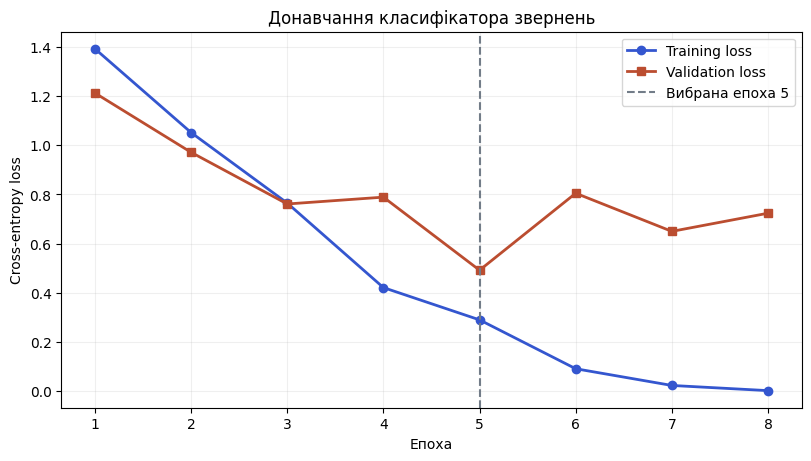

CPU times: user 381 ms, sys: 4.88 ms, total: 386 ms
Wall time: 1.33 s


In [9]:
%%time
curve = pd.DataFrame(history)
fig, axis = plt.subplots(figsize=(8, 4.5), layout="constrained")
axis.plot(curve["epoch"], curve["train_loss"], marker="o", linewidth=2, label="Training loss", color="#3456cf")
axis.plot(curve["epoch"], curve["val_loss"], marker="s", linewidth=2, label="Validation loss", color="#bb4d30")
axis.axvline(best_epoch, color="#727c88", linestyle="--", label=f"Вибрана епоха {best_epoch}")
axis.set(xlabel="Епоха", ylabel="Cross-entropy loss", title="Донавчання класифікатора звернень")
axis.set_xticks(curve["epoch"])
axis.grid(alpha=0.2)
axis.legend()
display(fig)
plt.close(fig)

## 1.5. Порівняння на відкладеному тесті

Після вибору епохи за валідацією повторюється оцінка на тому самому тесті. Таблиця нижче зіставляє передбачення на восьми заздалегідь вибраних рядках. Повний список помилок і матриця сплутувань показують, між якими чергами модель помиляється.

In [10]:
%%time
after = evaluate(model, loaders["test"])
assert after["truth"] == baseline["truth"]
test_table["Після"] = [id_to_label[index] for index in after["predictions"]]
test_table["P після"] = after["confidence"]
scores = pd.DataFrame([
    {"Модель": "Найчастіший клас", **majority},
    {"Модель": "Початкова голова", **{key: baseline[key] for key in ["accuracy", "macro_f1", "loss"]}},
    {"Модель": "Після донавчання", **{key: after[key] for key in ["accuracy", "macro_f1", "loss"]}},
])
display(scores.round(4))
display(test_table.loc[test_table["id"].isin(example_ids), ["id", "text", "label", "До", "Після", "P після"]].round(3))

class_report = classification_report(after["truth"], after["predictions"], labels=list(id_to_label),
    target_names=labels, output_dict=True, zero_division=0)
display(pd.DataFrame(class_report).T.loc[labels].round(4))
errors = test_table[test_table["label"] != test_table["Після"]]
print(f"Помилок: {len(errors)} із {len(test_table)}.")
display(errors[["id", "text", "label", "Після", "P після"]].round(3))

,Модель,accuracy,macro_f1,loss
0,Найчастіший клас,0.2500,0.1000,NaN
1,Початкова голова,0.2500,0.1000,1.3918
2,Після донавчання,0.7083,0.7147,0.7829


,id,text,label,До,Після,P після
1,test-access-02,"Викладач дав посилання, та воно пускає тільки ...",access,equipment,materials,0.656
6,test-access-07,"Є пароль від пошти, а другий фактор втрачено. ...",access,equipment,schedule,0.484
13,test-materials-02,У PDF з правилами немає сторінок 7–9. Викладіт...,materials,equipment,materials,0.997
18,test-materials-07,Замість матеріалів курсу за посиланням лежить ...,materials,equipment,materials,0.689
25,test-schedule-02,Після перестановки груп хочу уточнити дату зах...,schedule,equipment,access,0.864
30,test-schedule-07,"Перенесення в інший корпус є в оголошенні, але...",schedule,equipment,schedule,0.860
37,test-equipment-02,"Заняття починається, а сенсорна дошка не реагу...",equipment,equipment,access,0.636
42,test-equipment-07,"Кабель підключено, але порт мережі біля останн...",equipment,equipment,access,0.705


,precision,recall,f1-score,support
access,0.5385,0.5833,0.5600,12.0
materials,0.6250,0.8333,0.7143,12.0
schedule,0.8000,0.6667,0.7273,12.0
equipment,1.0000,0.7500,0.8571,12.0


Помилок: 14 із 48.


,id,text,label,Після,P після
1,test-access-02,"Викладач дав посилання, та воно пускає тільки ...",access,materials,0.656
2,test-access-03,"Архів лабораторних бачу, але завантаження забо...",access,materials,0.789
4,test-access-05,"Мені треба увійти до системи, але номер для ко...",access,materials,0.719
6,test-access-07,"Є пароль від пошти, а другий фактор втрачено. ...",access,schedule,0.484
10,test-access-11,Звернення про файл другорядне. Спершу треба ро...,access,materials,0.985
12,test-materials-01,"На порталі відкрився курс, але лист виправлень...",materials,access,0.904
15,test-materials-04,"Час консультації знаю. Потрібен перелік тем, я...",materials,schedule,0.611
24,test-schedule-01,"Файли для захисту є. Підкажіть, о котрій моя ч...",schedule,materials,0.980
25,test-schedule-02,Після перестановки груп хочу уточнити дату зах...,schedule,access,0.864
27,test-schedule-04,"Оновіть порядок захистів, бо моя підгрупа має ...",schedule,access,0.785


CPU times: user 168 ms, sys: 2.88 ms, total: 170 ms
Wall time: 330 ms


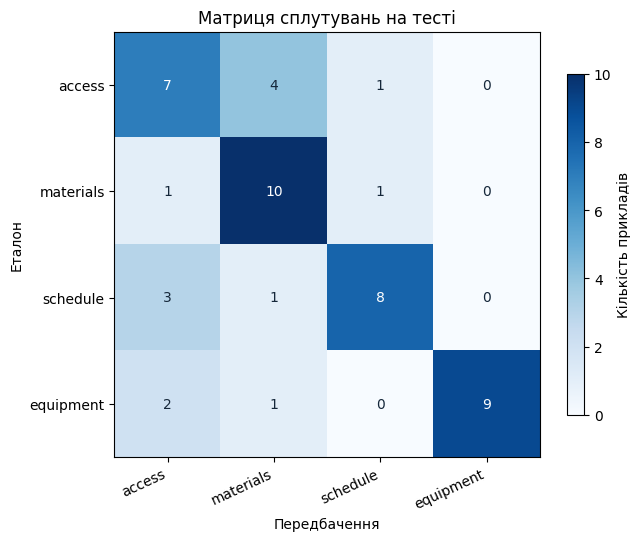

CPU times: user 361 ms, sys: 6.26 ms, total: 367 ms
Wall time: 843 ms


24535

In [11]:
%%time
matrix = confusion_matrix(after["truth"], after["predictions"], labels=list(id_to_label))
fig, axis = plt.subplots(figsize=(6.7, 5.3), layout="constrained")
image = axis.imshow(matrix, cmap="Blues", vmin=0)
axis.set_xticks(range(len(labels)), labels=labels, rotation=25, ha="right")
axis.set_yticks(range(len(labels)), labels=labels)
axis.set(xlabel="Передбачення", ylabel="Еталон", title="Матриця сплутувань на тесті")
for row in range(len(labels)):
    for column in range(len(labels)):
        value = matrix[row, column]
        axis.text(column, row, str(value), va="center", ha="center", color="white" if value > matrix.max() / 2 else "#15273a")
fig.colorbar(image, ax=axis, shrink=0.8, label="Кількість прикладів")
display(fig)
plt.close(fig)

project_measurements = {"device": str(device), "training_seconds": training_seconds, "peak_rss_gb": peak_cpu_gb,
    "peak_gpu_gb": peak_gpu_gb, "best_epoch": best_epoch, "history": history,
    "parameter_count": parameter_count, "trainable_count": trainable_count,
    "baseline": baseline, "majority": majority, "after": after, "examples": example_ids,
    "test_rows": test_table.to_dict("records"), "confusion_matrix": matrix.tolist(), "class_report": class_report}
Path("ft_project_measurements.json").write_text(json.dumps(project_measurements, ensure_ascii=False, indent=2), encoding="utf-8")

## 1.6. Мій звіт

**Задача і чому потрібне донавчання.** Класифікатор призначає україномовному зверненню студента одну з чотирьох черг факультету. Навчання на розмічених зверненнях переносить у модель локальне правило вибору категорії за головною дією. Голова енкодера повертає один клас за один прохід. Промпт або пошук документів були б окремими підходами, які в цьому експерименті не вимірювалися.

**Модель і дані.** Багатомовний DistilBERT із новою головою на 4 класи, ліцензія моделі Apache 2.0. Корпус із 240 вигаданих звернень, CC0 1.0. Розподіл 160/32/48 зроблено за групами сценаріїв. Перевірено унікальність і відсутність перетину груп між наборами.

**Метрика й результат до донавчання.** Основна метрика macro F1 надає однакову вагу класам. У baseline найчастішого класу accuracy 0.2500 і macro F1 0.1000. У моделі з початковою головою accuracy 0.2500 і macro F1 0.1000.

**Метод донавчання й гіперпараметри.** Оновлювалися останній шар і голова, разом 7,681,540 з 135,327,748 параметрів. AdamW, батч 8, максимум 96 токенів. Learning rate для останнього шару 8e-5, для голови 4e-4. У CPU-запуску цикл з 8 епох і валідацій тривав 33.02 с. Пік RSS процесу 1.098 GB. Для цього CPU-запуску VRAM не вимірювалась. У профілі T4 її пік виводиться клітинкою навчання.

**Результат після донавчання.** На тому самому тесті accuracy 0.7917, macro F1 0.7963, правильно 38 із 48 звернень. Вибрано епоху 6 за validation loss 0.5497. Пізніше train loss знизився до 0.0098, а validation loss виріс до 0.7202. Тому для тесту відновлено параметри з мінімальним validation loss.

**Аналіз помилок.** Найнижчий recall у `schedule` — 8 із 12. Три з цих звернень пішли в `access`, одне в `materials`. У `test-schedule-01` згадано наявні файли, а студент просить уточнити час захисту. Модель обрала `materials`. У `test-access-11` згадка файлу супроводжує прохання розблокувати авторизацію, але модель теж вибрала `materials`. Для `test-equipment-02` помилка виникла на новому типі обладнання, сенсорній дошці. Такі приклади показують, що для маршрутизації потрібно розпізнавати дію, пов’язану із запитом, і враховувати нові сценарії.

**Висновок.** Донавчання останнього шару й голови поліпшило оцінку на відкладених групах сценаріїв. Отримана якість описує малий синтетичний тест. Для робочого застосування потрібна перевірка на реальних зверненнях і перегляд повідомлень із кількома намірами.